# Protein structure from complementary measured spectra

## Problem

Infer helix, sheet, turn and other fractions for **four withheld proteins** from measured circular dichroism(CD) and attenuated-total-reflection infrared(IR) spectra. All four target proteins and their fractions are absent from the24-protein calibration library. The original SELCON3 run is the numerical reference; independent crystal fractions are a **structural proxy**, not same-condition truth. Solution CD and dry-film IR need not describe identical conformations. No synthetic observation replaces these actual processed measurements.

In [1]:
from pathlib import Path
import os,sys,time,json
root=Path.cwd()
if not (root/'src').is_dir():root=root.parent
os.chdir(root);sys.path.insert(0,str(root))
import numpy as np
import matplotlib.pyplot as plt
from src.preprocessing import load_data,prepare
from src.solvers import reconstruct
from src.visualization import fractions_plot,rms_error,NAMES,STRUCTURES
from evaluation.judge import metrics
data=load_data()
with np.load('notebooks/reference_outputs/upstream.npz',allow_pickle=False) as f:original={k:f[k] for k in f.files}
proxy=original['crystal_proxy']
wl=np.arange(240,174,-1);wn=np.arange(1600,1801);wn_joint=np.arange(1600,1721,2)
print('Measured targets:',data['observations'].shape,'independent calibration:',data['library_spectra'].shape)


Measured targets: (1, 4, 267) independent calibration: (1, 24, 267)


## Data

The author CD-IR28 pairing uses CD from SP175/SMP180 and IR from the RaSP50 dry-film remeasurement. The latter is distinct from the earlier liquid-sample RaSP50 release. We preserve all66CD samples(240–175nm) and201IR samples(1600–1800cm⁻¹), loaded float32 as in the original code. IR values have already been baseline-subtracted, zeroed at1718cm⁻¹ and maximum-normalized. File-specific scanner serials, concentrations and pathlengths are not present in this processed archive, so raw absorbance cannot be reconstructed.

Joint analysis selects1600–1720cm⁻¹ at2cm⁻¹ spacing; these61bins exactly equal the author's reduced file. IR-only comparison uses all201public IR bins. Separate modality axes below preserve their different units.

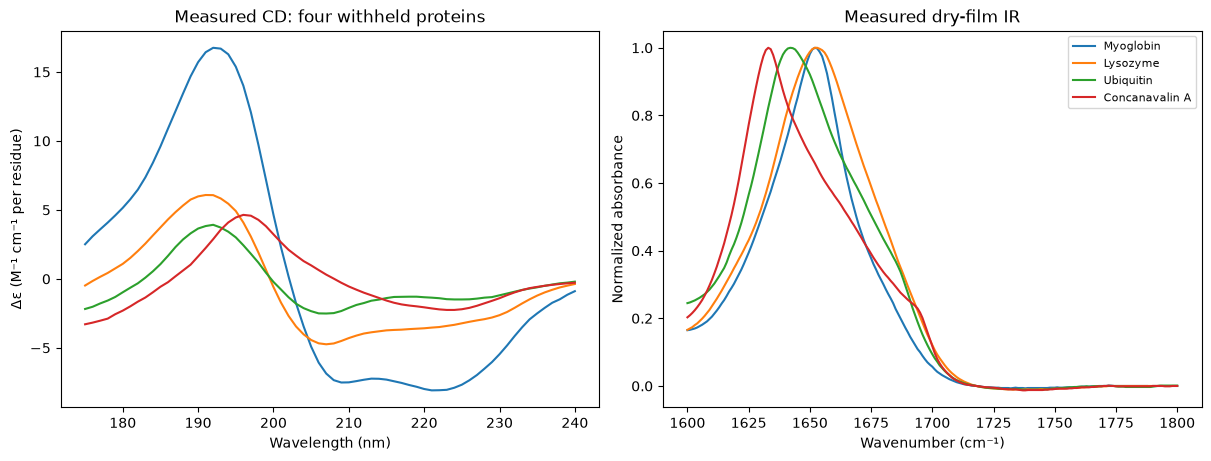

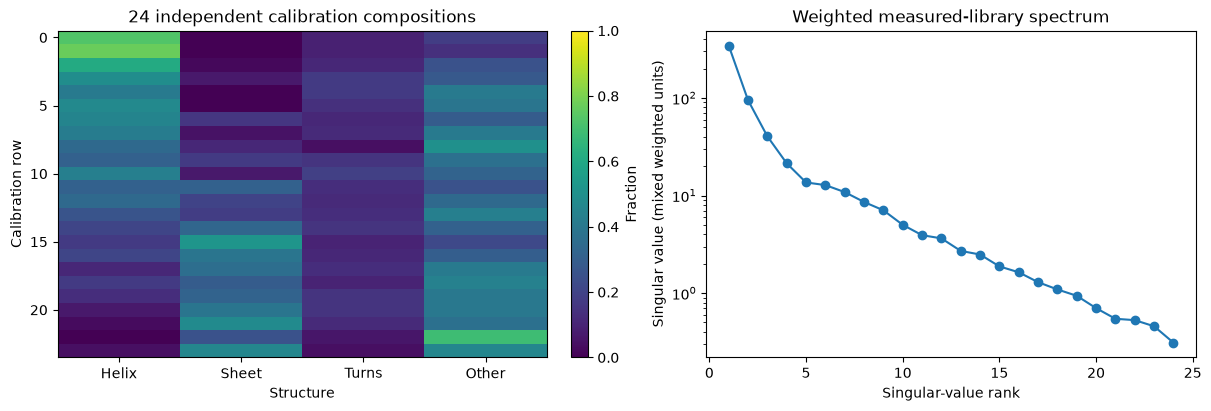

In [2]:
fig,ax=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
for i,name in enumerate(NAMES):
    ax[0].plot(wl,data['observations'][0,i,:66],label=name)
    ax[1].plot(wn,data['observations'][0,i,66:],label=name)
ax[0].set(xlabel='Wavelength (nm)',ylabel='Δε (M⁻¹ cm⁻¹ per residue)',title='Measured CD: four withheld proteins')
ax[1].set(xlabel='Wavenumber (cm⁻¹)',ylabel='Normalized absorbance',title='Measured dry-film IR');ax[1].legend(fontsize=8);plt.show()
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
im=ax[0].imshow(data['library_fractions'][0],aspect='auto',vmin=0,vmax=1,cmap='viridis')
ax[0].set_xticks(range(4),STRUCTURES);ax[0].set(title='24 independent calibration compositions',xlabel='Structure',ylabel='Calibration row');fig.colorbar(im,ax=ax[0],label='Fraction')
A,F,Q=prepare(data);singular=np.linalg.svd(A,compute_uv=False)
ax[1].semilogy(np.arange(1,len(singular)+1),singular,'o-');ax[1].set(title='Weighted measured-library spectrum',xlabel='Singular-value rank',ylabel='Singular value (mixed weighted units)');plt.show()


## Physics

The empirical peptide mixture model is $q\approx Bf$ and $A\approx BF$, where $q$ is a target spectrum, $f$ its four fractions, $B$ effective structural spectra, $A$ calibration spectra and $F$ calibration fractions. Equivalently, spectral-subspace coefficients $c$ give $q\approx Ac$ and $f\approx Fc$. Sequence and measurement condition perturb the common-basis approximation, so exact composition identifiability is limited.

After a singular decomposition $A=USV^T$, a rank-$r$ candidate is
$$
\hat f=F V_r S_r^{+}U_r^Tq.
$$
Here $r$ is the retained rank, subscript$r$ selects its singular vectors and $+$ denotes the pseudoinverse. This is one operator inside the full self-consistent selection method, not a replacement of that method with a single regression.

## Method

The complete local SELCON3 pipeline computes an independent rank-five helix estimate, sorts the24calibration spectra by measured spectral distance, augments the library with the target and a provisional fraction vector, and iterates over prefixes and ranks. It filters near-unit sums and lower bounds, updates the provisional estimate to self-consistency, then applies spectral-refit and helix-selection rules. The final result averages retained candidate fractions and refits. Population spread across retained candidates is a selection diagnostic, not a posterior uncertainty interval. The original fallback to SELCON2 is preserved and reported.

The default joint calculation multiplies the61IR bins by15 before fitting and divides the IR refit by15 for output. Small signed fractions remain unchanged; clipping or forcing an exact sum would alter the original method. The next cell actively reconstructs all four targets.

In [3]:
start=time.perf_counter();fresh,details=reconstruct(data);runtime=time.perf_counter()-start
np.savez_compressed('notebooks/reference_outputs/cleaned_measurements.npz',**fresh)
reference={'reconstruction':np.stack([original[f'scale15_target{i}_sel3'] for i in range(4)])[None],
           'spectra':np.stack([original[f'scale15_target{i}_Mean_refit_prot'] for i in range(4)])[None]}
reference['spectra'][:,:,66:]/=15
print('Fresh reconstruction seconds:',runtime)
print(json.dumps(metrics(fresh,reference),indent=2))
for name,d in zip(NAMES,details):print(name,'iterations',d['attempts'],'retained',len(d['refit_np_param']),'fallback',d['fallback'],'fraction sum',d['fractions'].sum())


Fresh reconstruction seconds: 0.08621829998446628
{
  "fraction_max_error": 0.0,
  "cd_refit_rmse": 0.0,
  "ir_refit_rmse": 0.0,
  "fraction_sum_deviation": 0.034248374532733994,
  "fraction_min": -0.009975061264275217
}
Myoglobin iterations 2 retained 13 fallback False fraction sum 0.9866715269537591
Lysozyme iterations 3 retained 7 fallback False fraction sum 1.005514679711287
Ubiquitin iterations 5 retained 9 fallback False fraction sum 0.9857729101043661
Concanavalin A iterations 6 retained 10 fallback True fraction sum 0.965751625467266


## Results

The following panels compare fresh numerical fractions with this task's original-code run and the independent crystallographic proxy. Crystal annotations are deliberately private for the targets. Agreement with the original run checks extraction; mismatch with the proxy can reflect spectroscopy, library coverage or solution/dry-film/crystal differences.

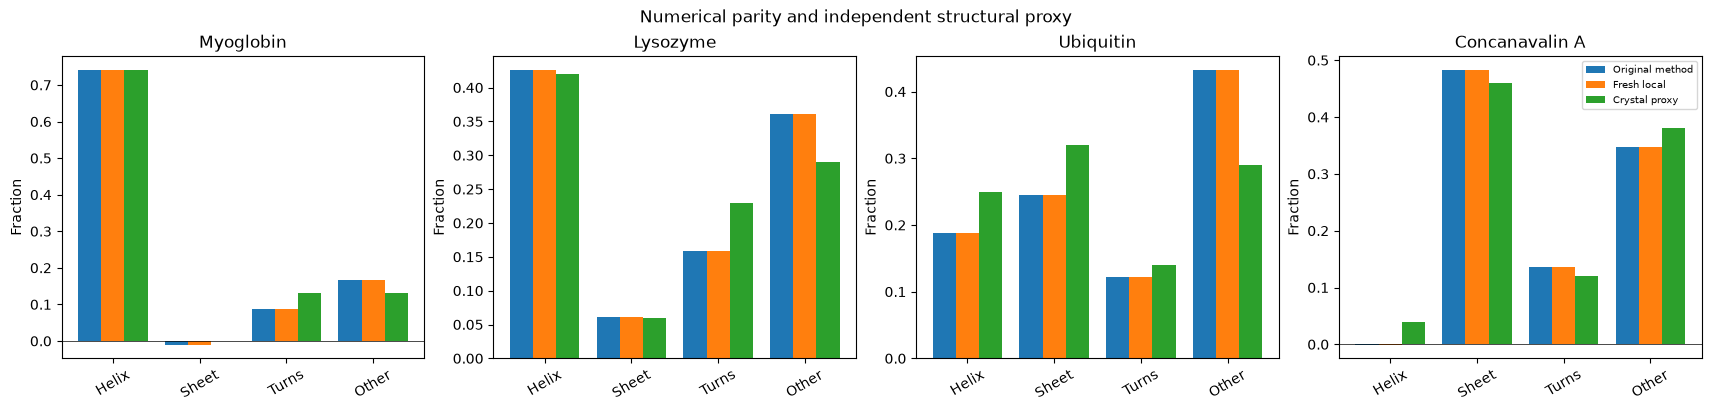

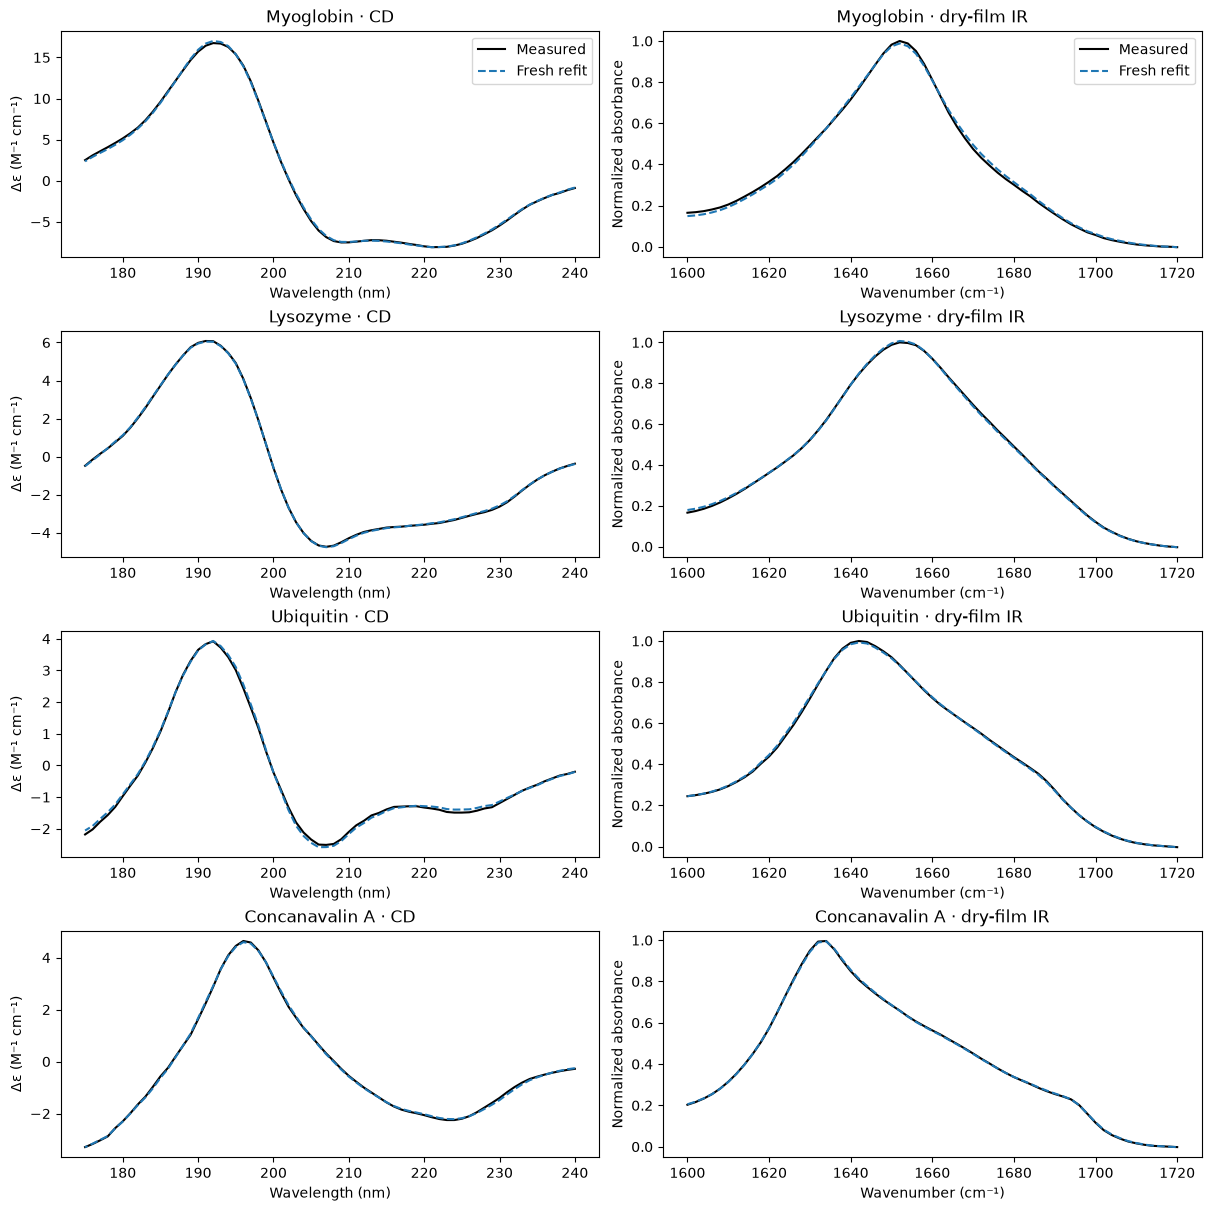

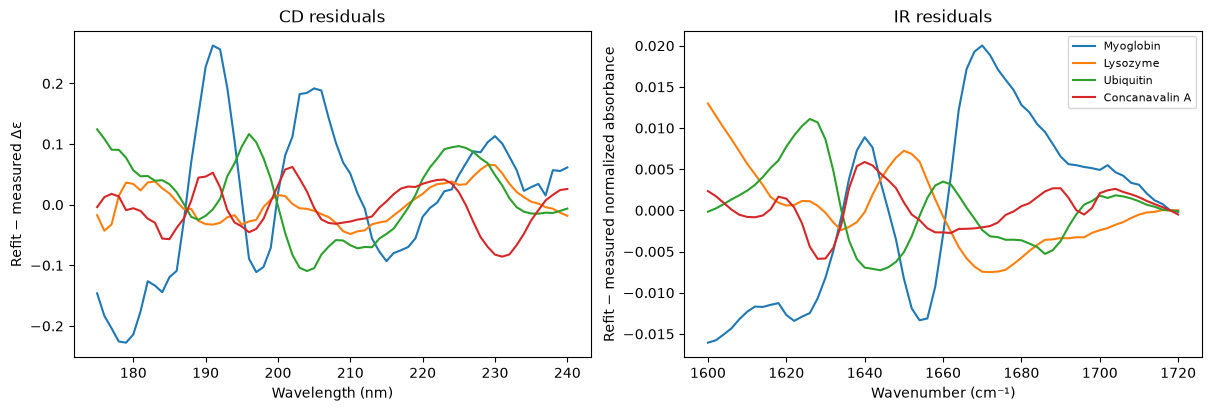

In [4]:
fractions_plot({'Original method':reference['reconstruction'][0],'Fresh local':fresh['reconstruction'][0],'Crystal proxy':proxy},'Numerical parity and independent structural proxy');plt.show()
fig,ax=plt.subplots(4,2,figsize=(12,12),layout='constrained')
for i,name in enumerate(NAMES):
    ax[i,0].plot(wl,data['observations'][0,i,:66],color='black',label='Measured')
    ax[i,0].plot(wl,fresh['spectra'][0,i,:66],'--',label='Fresh refit')
    ax[i,1].plot(wn_joint,data['observations'][0,i,66:187:2],color='black',label='Measured')
    ax[i,1].plot(wn_joint,fresh['spectra'][0,i,66:],'--',label='Fresh refit')
    ax[i,0].set(title=name+' · CD',xlabel='Wavelength (nm)',ylabel='Δε (M⁻¹ cm⁻¹)')
    ax[i,1].set(title=name+' · dry-film IR',xlabel='Wavenumber (cm⁻¹)',ylabel='Normalized absorbance')
ax[0,0].legend();ax[0,1].legend();plt.show()
fig,ax=plt.subplots(1,2,figsize=(12,4),layout='constrained')
for i,name in enumerate(NAMES):
    ax[0].plot(wl,fresh['spectra'][0,i,:66]-data['observations'][0,i,:66],label=name)
    ax[1].plot(wn_joint,fresh['spectra'][0,i,66:]-data['observations'][0,i,66:187:2],label=name)
ax[0].set(xlabel='Wavelength (nm)',ylabel='Refit − measured Δε',title='CD residuals')
ax[1].set(xlabel='Wavenumber (cm⁻¹)',ylabel='Refit − measured normalized absorbance',title='IR residuals');ax[1].legend(fontsize=8);plt.show()


The paper's relevant comparison is complementary modalities, not only the default fit. All three modes below are recomputed from public observations with the complete local SELCON pipeline and compared against separately frozen original runs. The subsequent scaling sweep tests how relative block weighting changes inferred fractions and modality-specific residuals. These comparisons do not optimize against the hidden crystal annotations.

IR scale 0 maximum original fraction discrepancy 0.0
IR scale 1 maximum original fraction discrepancy 0.0
IR scale 5 maximum original fraction discrepancy 0.0
IR scale 10 maximum original fraction discrepancy 0.0
IR scale 15 maximum original fraction discrepancy 0.0
IR scale 20 maximum original fraction discrepancy 0.0
IR-only -1 maximum original fraction discrepancy 0.0


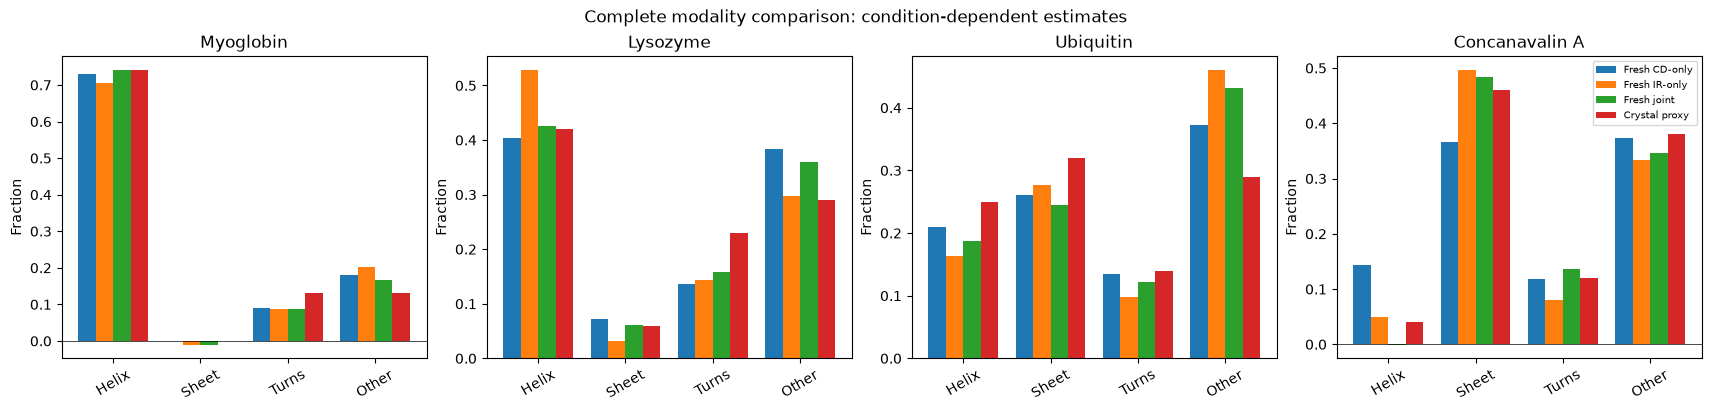

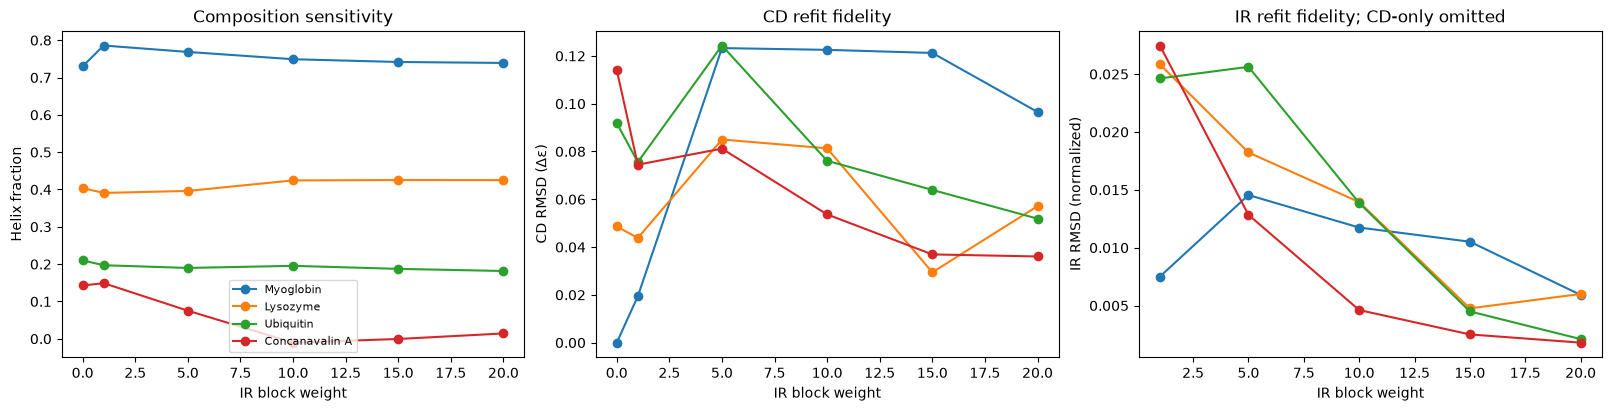

In [5]:
comparisons={};comparison_details={}
for scale in [0,1,5,10,15,20,-1]:
    result,diag=reconstruct(data,ir_scale=scale if scale>=0 else 15,mode='ir' if scale==-1 else 'joint')
    comparisons[scale]=result;comparison_details[scale]=diag
    parity=max(float(np.max(np.abs(diag[i]['fractions']-original[f'scale{scale}_target{i}_sel3']))) for i in range(4))
    print('IR scale' if scale>=0 else 'IR-only',scale,'maximum original fraction discrepancy',parity)
fractions_plot({'Fresh CD-only':comparisons[0]['reconstruction'][0],'Fresh IR-only':comparisons[-1]['reconstruction'][0],'Fresh joint':comparisons[15]['reconstruction'][0],'Crystal proxy':proxy},'Complete modality comparison: condition-dependent estimates');plt.show()
scales=[0,1,5,10,15,20]
fig,ax=plt.subplots(1,3,figsize=(16,4),layout='constrained')
for i,name in enumerate(NAMES):
    ax[0].plot(scales,[comparisons[s]['reconstruction'][0,i,0] for s in scales],'o-',label=name)
    ax[1].plot(scales,[rms_error(comparisons[s]['spectra'][0,i,:66],data['observations'][0,i,:66]) for s in scales],'o-')
    ax[2].plot(scales[1:],[rms_error(comparisons[s]['spectra'][0,i,66:],data['observations'][0,i,66:187:2]) for s in scales[1:]],'o-')
ax[0].set(xlabel='IR block weight',ylabel='Helix fraction',title='Composition sensitivity');ax[0].legend(fontsize=8)
ax[1].set(xlabel='IR block weight',ylabel='CD RMSD (Δε)',title='CD refit fidelity')
ax[2].set(xlabel='IR block weight',ylabel='IR RMSD (normalized)',title='IR refit fidelity; CD-only omitted');plt.show()


The final diagnostics preserve the original candidate-refit comparison and explicitly distinguish candidate variability from sampling uncertainty. Individual retained subspace refits and their mean show how multiple valid solutions can produce similar spectra. Bars compare fraction error against a condition-mismatched crystal proxy; no modality is guaranteed to win on every protein.

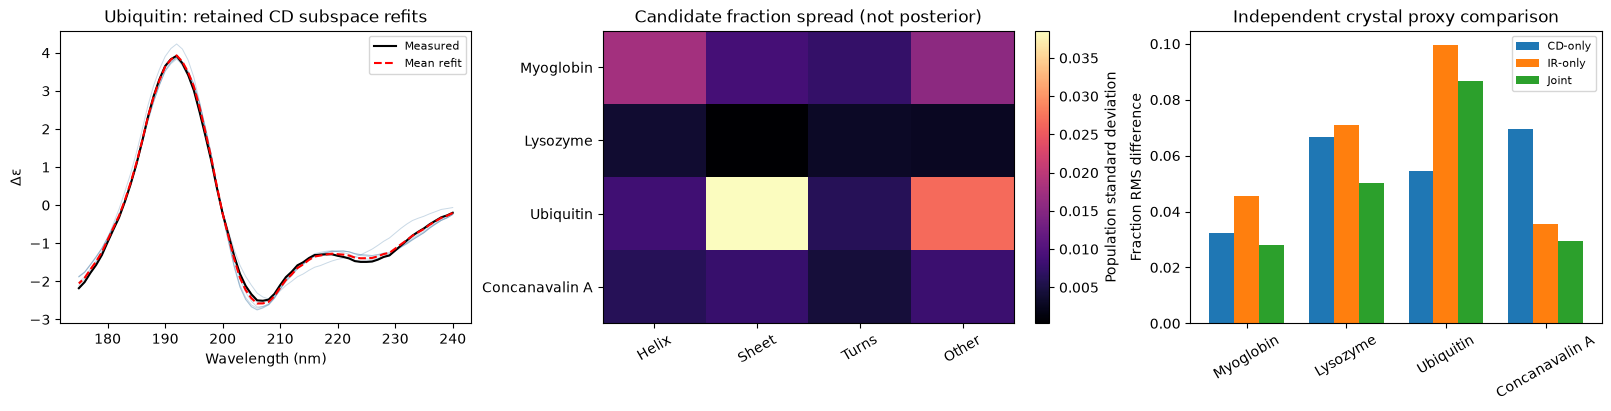

In [6]:
fig,ax=plt.subplots(1,3,figsize=(16,4),layout='constrained')
i=2;d=details[i]
for line in d['ensemble_spectra'].T:ax[0].plot(wl,line[:66],color='#4f83ad',alpha=.3,lw=.7)
ax[0].plot(wl,data['observations'][0,i,:66],color='black',label='Measured')
ax[0].plot(wl,fresh['spectra'][0,i,:66],'r--',label='Mean refit');ax[0].set(title='Ubiquitin: retained CD subspace refits',xlabel='Wavelength (nm)',ylabel='Δε');ax[0].legend(fontsize=8)
spread=np.stack([d['spread'] for d in details]);im=ax[1].imshow(spread,aspect='auto',cmap='magma')
ax[1].set_xticks(range(4),STRUCTURES,rotation=30);ax[1].set_yticks(range(4),NAMES);ax[1].set_title('Candidate fraction spread (not posterior)');fig.colorbar(im,ax=ax[1],label='Population standard deviation')
for j,(scale,label) in enumerate([(0,'CD-only'),(-1,'IR-only'),(15,'Joint')]):
    errors=np.sqrt(np.mean((comparisons[scale]['reconstruction'][0]-proxy)**2,axis=1))
    ax[2].bar(np.arange(4)+(j-1)*.25,errors,.25,label=label)
ax[2].set_xticks(range(4),NAMES,rotation=30);ax[2].set(ylabel='Fraction RMS difference',title='Independent crystal proxy comparison');ax[2].legend(fontsize=8);plt.show()


## Conclusion

The fresh complete SELCON3 implementation reproduces the original default and all modality/weighting comparisons on the exact measured spectra. CD and IR constrain overlapping but different spectral features; neither numerical parity nor a good refit makes the inverse unique. The four unknown compositions were never supplied as calibration. Slight negative fractions and nonunit sums reflect the published approximate selection rules and remain visible. Differences from crystal fractions are evidence of an imperfect structural proxy and model/sample-condition mismatch, not grounds to label reconstructed fractions as physical truth.